# Exploration: `ssh_bruteforce.csv`

Dieses Notebook untersucht den SSH-Bruteforce-Datensatz (Flow-Features aus `flowextractor`) und evaluiert anschließend
ein `AttackDetectionNet` aus `src/flowextractor/model/model.py`, trainiert mit genau der Vorverarbeitung
(`normalize_training_data`) und dem chronologischen 80/20-Split aus `model.main()`.

**Inhalt**
1. Überblick & Datenqualität
2. Klassenverteilung & zeitlicher Verlauf
3. Feature-Verteilungen (alle Flows und nur SSH-Flows)
4. Ports & IP-Adressen
5. Korrelationen & normalisierte Features
6. Modelltraining
7. Evaluation (Metriken, Konfusionsmatrix, ROC/PR, Schwellwerte)
8. Robustheit: nur SSH-Flows, Port-Baseline, unbekannte Angreifer-IPs, Ablation ohne Ports
9. **Feature Importance** (Permutation Importance, Gradient × Input)
10. Fehleranalyse & Fazit

In [19]:
import os
os.environ["TQDM_DISABLE"] = "1"  # tqdm-Fortschrittsbalken aus fit() würden das Notebook aufblähen

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from flowextractor.model.model import (
    AttackDetectionNet, normalize_training_data, print_metrics, FEATURE_COLUMNS, LOG_SCALED_COLUMNS,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV_PATH = ROOT / "ssh_bruteforce.csv"

SEED = 42
EPOCHS = 20        # wie der CLI-Default von flowmodel
BATCH_SIZE = 32    # wie der CLI-Default von flowmodel
CUTOFF = 0.5

# Das Netz ist winzig: auf der CPU ist ein Thread ~8x schneller als Multi-Threading (Sync-Overhead)
torch.set_num_threads(1)

# Farben: Klasse = Identität -> feste kategoriale Slots
C_BENIGN, C_MAL, C_ALT = "#2a78d6", "#eb6834", "#1baf7a"
CLASS_COLORS = {"benign": C_BENIGN, "malicious": C_MAL}
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": INK_MUTED, "axes.labelcolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 160)

## 1. Überblick & Datenqualität

In [20]:
raw = pd.read_csv(CSV_PATH)
raw["is_mal"] = (raw["Label"] == "malicious").astype(int)
raw["is_ssh"] = (raw["Source Port"] == 22) | (raw["Destination Port"] == 22)
print(f"Datei: {CSV_PATH.name} ({CSV_PATH.stat().st_size / 1e6:.1f} MB)")
print(f"Flows: {len(raw):,}  |  Spalten: {raw.shape[1] - 2}")
raw.head()

Datei: ssh_bruteforce.csv (35.1 MB)
Flows: 313,239  |  Spalten: 15


,Flow Hash,Source IP,Destination IP,Number of Packets,Source Port,Destination Port,Average Packet Size,Minimum Packet Size,Maximum Packet Size,Total Bytes,IAT Min,IAT Max,IAT Mean,Label,Attack Type,is_mal,is_ssh
0,-4417618825813653950,85.217.149.70,37.60.229.253,1,59948,6516,66.0000,66,66,66,inf,0.0000,0.0000,benign,NaN,0,False
1,169730293831035728,37.60.229.253,85.217.149.70,1,6516,59948,54.0000,54,54,54,inf,0.0000,0.0000,benign,NaN,0,False
2,-8589617419867487974,85.217.140.1,37.60.229.253,1,53539,11898,66.0000,66,66,66,inf,0.0000,0.0000,benign,NaN,0,False
3,4306986738523343389,37.60.229.253,85.217.140.1,1,11898,53539,54.0000,54,54,54,inf,0.0000,0.0000,benign,NaN,0,False
4,3679926442995352880,85.217.140.48,37.60.229.253,1,55395,49209,66.0000,66,66,66,inf,0.0000,0.0000,benign,NaN,0,False


In [21]:
num_cols = raw.select_dtypes("number").columns.drop(["is_mal", "Flow Hash"])
quality = pd.DataFrame({
    "dtype": raw[num_cols].dtypes.astype(str),
    "NaN": raw[num_cols].isna().sum(),
    "inf": np.isinf(raw[num_cols]).sum(),
    "Null-Werte": (raw[num_cols] == 0).sum(),
    "unique": raw[num_cols].nunique(),
})
quality

,dtype,NaN,inf,Null-Werte,unique
Number of Packets,int64,0,0,0,387
Source Port,int64,0,0,1,64975
Destination Port,int64,0,0,1,64995
Average Packet Size,float64,0,0,0,10288
Minimum Packet Size,int64,0,0,0,291
Maximum Packet Size,int64,0,0,0,1046
Total Bytes,int64,0,0,0,7695
IAT Min,float64,0,246168,3887,24902
IAT Max,float64,0,0,246171,65936
IAT Mean,float64,0,0,246171,66862


In [22]:
print("Label-Werte:", raw["Label"].value_counts(dropna=False).to_dict())
print("Attack Type:", raw["Attack Type"].value_counts(dropna=False).to_dict())
single = raw["Number of Packets"] == 1
print(f"\nFlows mit genau 1 Paket: {single.sum():,} ({single.mean():.1%})  -> IAT Min = inf bei {np.isinf(raw['IAT Min']).sum():,} Flows")
print(f"inf in 'IAT Min' nur bei 1-Paket-Flows: {np.isinf(raw.loc[~single, 'IAT Min']).sum() == 0}")

dup = raw["Flow Hash"].duplicated(keep=False)
conflict = raw[dup].groupby("Flow Hash")["Label"].nunique().gt(1).sum()
print(f"\nFlow-Hashes mehrfach vorhanden: {raw['Flow Hash'].duplicated().sum():,} Duplikate "
      f"({dup.sum():,} betroffene Zeilen), davon Hashes mit widersprüchlichem Label: {conflict}")
print(f"Komplett identische Feature-Zeilen (ohne Hash): {raw.drop(columns=['Flow Hash']).duplicated().sum():,}")

Label-Werte: {'benign': 281933, 'malicious': 31306}
Attack Type: {nan: 281933, 'ssh_brute_force': 31306}

Flows mit genau 1 Paket: 246,168 (78.6%)  -> IAT Min = inf bei 246,168 Flows
inf in 'IAT Min' nur bei 1-Paket-Flows: True

Flow-Hashes mehrfach vorhanden: 6,011 Duplikate (8,819 betroffene Zeilen), davon Hashes mit widersprüchlichem Label: 64
Komplett identische Feature-Zeilen (ohne Hash): 1,289


**Hinweis:** `Attack Type` ist für benigne Flows `n/a` und wird von pandas als NaN gelesen. `IAT Min = inf` entsteht bei
Flows mit nur einem Paket; `normalize_training_data` ersetzt diese Werte durch 0.

## 2. Klassenverteilung & zeitlicher Verlauf

,Flows,Anteil
Label,,
benign,281933,90.01%
malicious,31306,9.99%


Imbalance-Verhältnis benign : malicious = 9.0 : 1


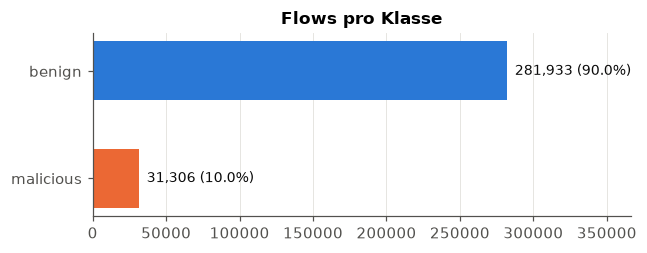

In [23]:
counts = raw["Label"].value_counts()
share = raw["Label"].value_counts(normalize=True)
display(pd.DataFrame({"Flows": counts, "Anteil": share.map("{:.2%}".format)}))
print(f"Imbalance-Verhältnis benign : malicious = {counts['benign'] / counts['malicious']:.1f} : 1")

fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(counts.index, counts.values, color=[CLASS_COLORS[c] for c in counts.index], height=0.55)
for i, (c, v) in enumerate(counts.items()):
    ax.text(v, i, f"  {v:,} ({share[c]:.1%})", va="center", color=INK, fontsize=9)
ax.set_xlim(0, counts.max() * 1.3)
ax.set_title("Flows pro Klasse")
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Die Flows werden in Aufnahme-Reihenfolge an die CSV angehängt. Der Anteil bösartiger Flows über die Zeit zeigt, ob der
chronologische Split von `model.main()` (erste 80 % Training, letzte 20 % Test) repräsentativ ist.

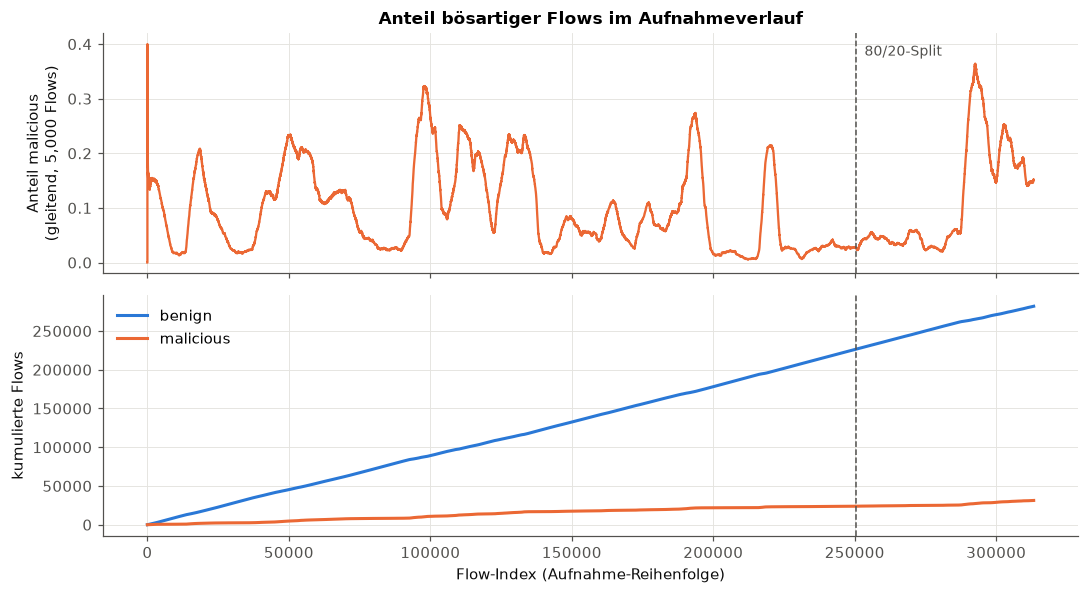

,Flows,malicious,Anteil malicious
Train (erste 80 %),250591,23860,0.0952
Test (letzte 20 %),62648,7446,0.1189


In [24]:
split_idx = int(len(raw) * 0.8)
window = 5000
rolling = raw["is_mal"].rolling(window, min_periods=1).mean()

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(rolling.index, rolling.values, color=C_MAL, linewidth=1.5)
axes[0].set_ylabel(f"Anteil malicious\n(gleitend, {window:,} Flows)")
axes[0].set_title("Anteil bösartiger Flows im Aufnahmeverlauf")
axes[1].plot(raw.index, (1 - raw["is_mal"]).cumsum(), color=C_BENIGN, label="benign")
axes[1].plot(raw.index, raw["is_mal"].cumsum(), color=C_MAL, label="malicious")
axes[1].set_ylabel("kumulierte Flows")
axes[1].set_xlabel("Flow-Index (Aufnahme-Reihenfolge)")
axes[1].legend(loc="upper left")
for ax in axes:
    ax.axvline(split_idx, color=INK_MUTED, linestyle="--", linewidth=1)
axes[0].text(split_idx, axes[0].get_ylim()[1] * 0.95, "  80/20-Split", color=INK_MUTED, va="top", fontsize=9)
plt.tight_layout()
plt.show()

split_stats = pd.DataFrame({
    "Flows": [split_idx, len(raw) - split_idx],
    "malicious": [raw["is_mal"][:split_idx].sum(), raw["is_mal"][split_idx:].sum()],
}, index=["Train (erste 80 %)", "Test (letzte 20 %)"])
split_stats["Anteil malicious"] = split_stats["malicious"] / split_stats["Flows"]
split_stats

## 3. Feature-Verteilungen

In [25]:
feature_stats = raw.groupby("Label")[FEATURE_COLUMNS].median().T
feature_stats.columns = [f"Median {c}" for c in feature_stats.columns]
mean_stats = raw.replace(np.inf, np.nan).groupby("Label")[FEATURE_COLUMNS].mean().T
feature_stats["Mean benign"] = mean_stats["benign"]
feature_stats["Mean malicious"] = mean_stats["malicious"]
feature_stats

,Median benign,Median malicious,Mean benign,Mean malicious
Number of Packets,1.0000,12.0000,4.1118,12.6475
Source Port,"40,229.0000",22.0000,"35,526.2027","22,614.1659"
Destination Port,"40,166.0000","1,024.0000","35,482.0597","22,648.7395"
Average Packet Size,60.0000,184.6667,77.2163,183.5496
Minimum Packet Size,60.0000,66.0000,62.1818,65.6878
Maximum Packet Size,60.0000,"1,042.0000",147.2347,"1,031.9281"
Total Bytes,66.0000,"2,463.0000","1,082.7851","2,343.1471"
IAT Min,inf,0.0000,0.7684,0.0094
IAT Max,0.0000,3.2443,0.9186,3.2879
IAT Mean,0.0000,0.3613,0.2797,0.4863


In [26]:
raw.replace(np.inf, np.nan).groupby("Label")[LOG_SCALED_COLUMNS].describe().T.unstack(level=1)

Label                     benign                                                                          malicious                                         \
                           count       mean         std     min     25%     50%     75%             max       count       mean      std     min        25%   
Number of Packets   281,933.0000     4.1118    216.3625  1.0000  1.0000  1.0000  1.0000     67,813.0000 31,306.0000    12.6475   3.0409  1.0000    12.0000   
Average Packet Size 281,933.0000    77.2163    111.0886 54.0000 54.0000 60.0000 66.0000     12,105.3789 31,306.0000   183.5496  44.0575 54.0000   162.5714   
Minimum Packet Size 281,933.0000    62.1818     25.0086 54.0000 54.0000 60.0000 66.0000      1,514.0000 31,306.0000    65.6878   2.2013 54.0000    66.0000   
Maximum Packet Size 281,933.0000   147.2347    446.1155 54.0000 54.0000 60.0000 66.0000     32,266.0000 31,306.0000 1,031.9281 293.5014 54.0000 1,042.0000   
Total Bytes         281,933.0000 1,082.7851 91,437.8738 54.0000 54.0000 66.0000 66.0000 44,315,096.0000 31,306.0000 2,343.1471 714.5138 54.0000 2,200.0000   
IAT Min              35,845.0000     0.7684      4.2677  0.0000  0.0000  0.0024  0.1557         85.9614 31,226.0000     0.0094   0.2147  0.0000     0.0000   
IAT Max             281,933.0000     0.9186      5.0060  0.0000  0.0000  0.0000  0.0000         90.3020 31,306.0000     3.2879   3.3349  0.0000     2.2448   
IAT Mean            281,933.0000     0.2797      1.9256  0.0000  0.0000  0.0000  0.0000         85.9614 31,306.0000     0.4863   0.6855  0.0000     0.2646   

Label                                                  
                           50%        75%         max  
Number of Packets      12.0000    14.0000     38.0000  
Average Packet Size   184.6667   214.4167    752.1000  
Minimum Packet Size    66.0000    66.0000    150.0000  
Maximum Packet Size 1,042.0000 1,186.0000  2,354.0000  
Total Bytes         2,463.0000 2,589.0000 11,959.0000  
IAT Min                 0.0000     0.0002     32.0084  
IAT Max                 3.2443     3.7128     79.3867  
IAT Mean                0.3613     0.4973     32.0084

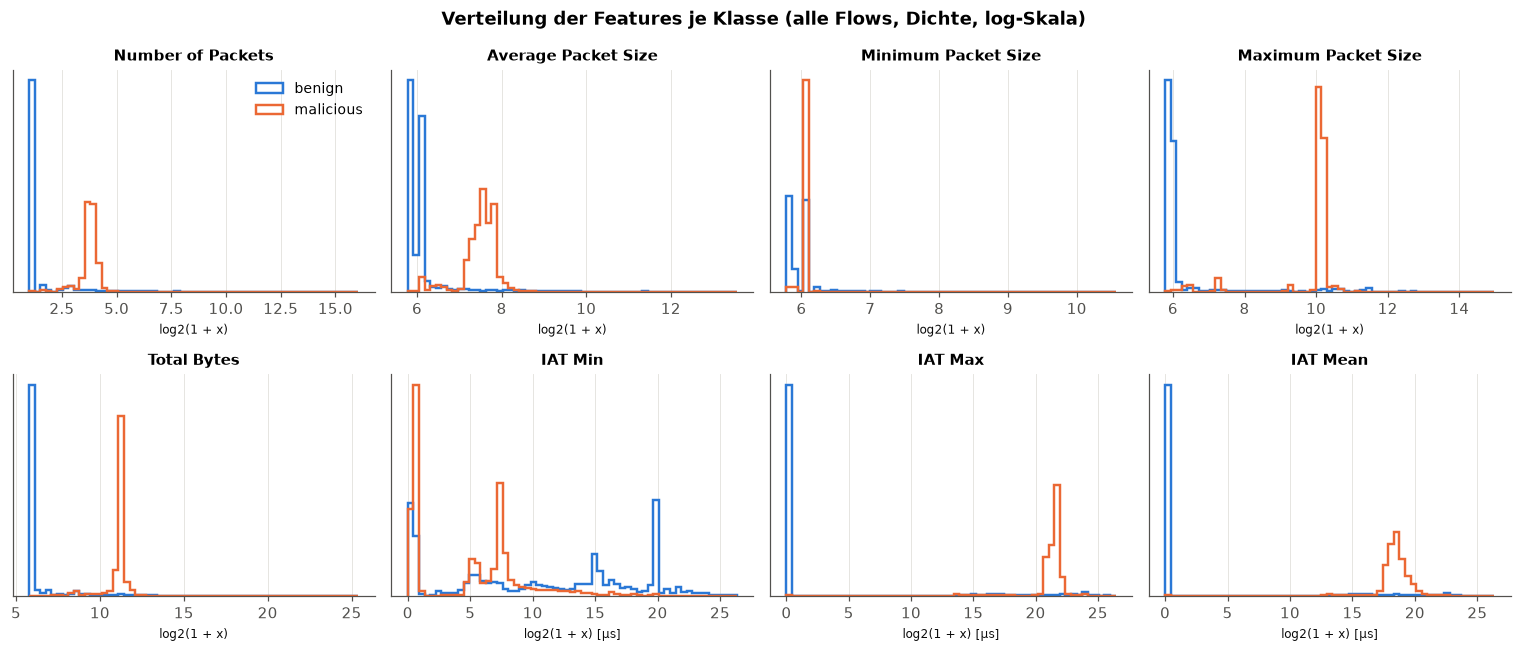

In [27]:
def class_hist(data, title, columns=LOG_SCALED_COLUMNS, bins=60):
    fig, axes = plt.subplots(2, 4, figsize=(14, 6))
    for ax, col in zip(axes.flat, columns):
        vals = data[col].replace(np.inf, np.nan)
        if col.startswith("IAT"):
            vals = vals * 1e6  # Mikrosekunden, wie in normalize_training_data
        logged = np.log2(1 + vals)
        edges = np.linspace(np.nanmin(logged), np.nanmax(logged), bins)
        for label, color in CLASS_COLORS.items():
            v = logged[data["Label"] == label].dropna()
            ax.hist(v, bins=edges, density=True, histtype="step", linewidth=1.6, color=color, label=label)
        ax.set_title(col, fontsize=10)
        ax.set_xlabel("log2(1 + x)" + (" [µs]" if col.startswith("IAT") else ""), fontsize=8)
        ax.set_yticks([])
    axes.flat[0].legend(fontsize=9)
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()

class_hist(raw, "Verteilung der Features je Klasse (alle Flows, Dichte, log-Skala)")

Alle bösartigen Flows laufen über Port 22. Die eigentlich schwierige Frage ist daher, wie gut sich Bruteforce-Flows von
**legitimem SSH-Verkehr** unterscheiden lassen. Deshalb dieselben Verteilungen nur für SSH-Flows:

Label,benign,malicious,All
is_ssh,,,
SSH (Port 22),7244,31306,38550
kein SSH,274689,0,274689
All,281933,31306,313239


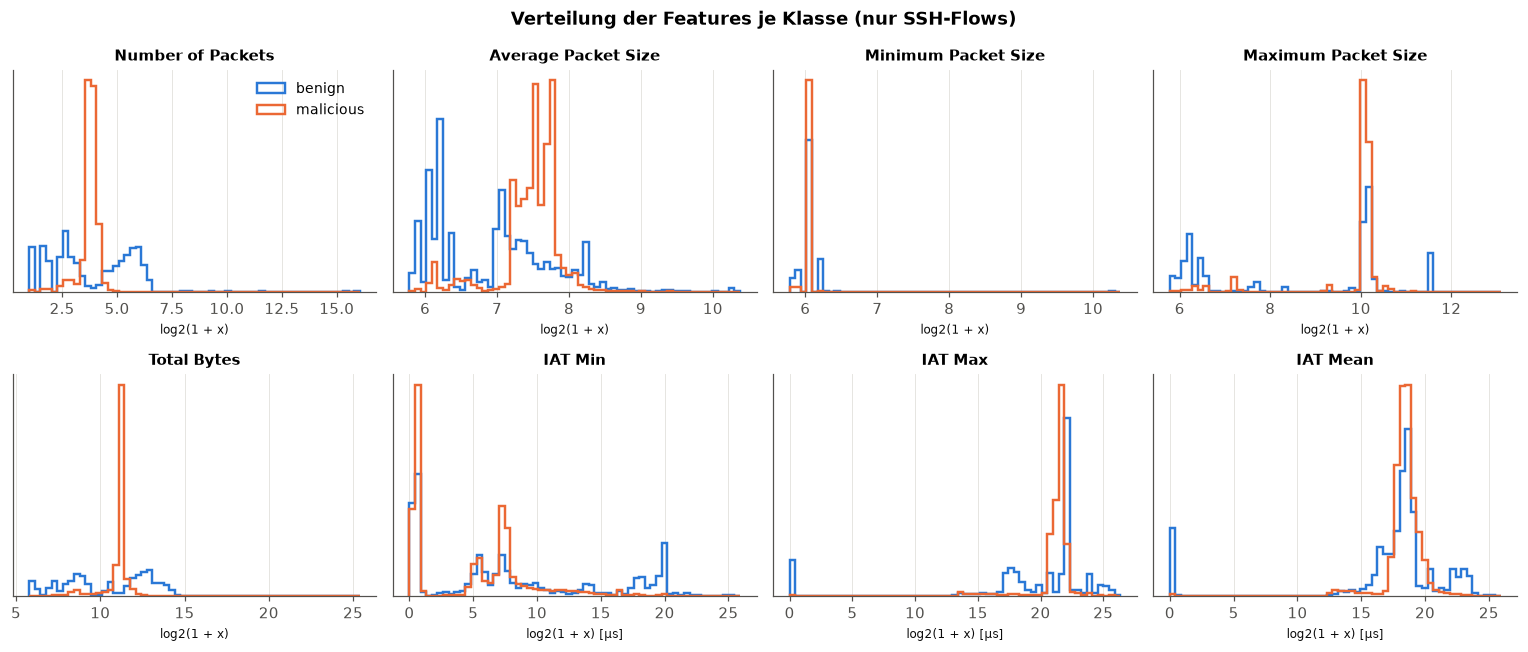

In [28]:
ssh = raw[raw["is_ssh"]]
display(pd.crosstab(raw["is_ssh"].map({True: "SSH (Port 22)", False: "kein SSH"}), raw["Label"], margins=True))
class_hist(ssh, "Verteilung der Features je Klasse (nur SSH-Flows)")

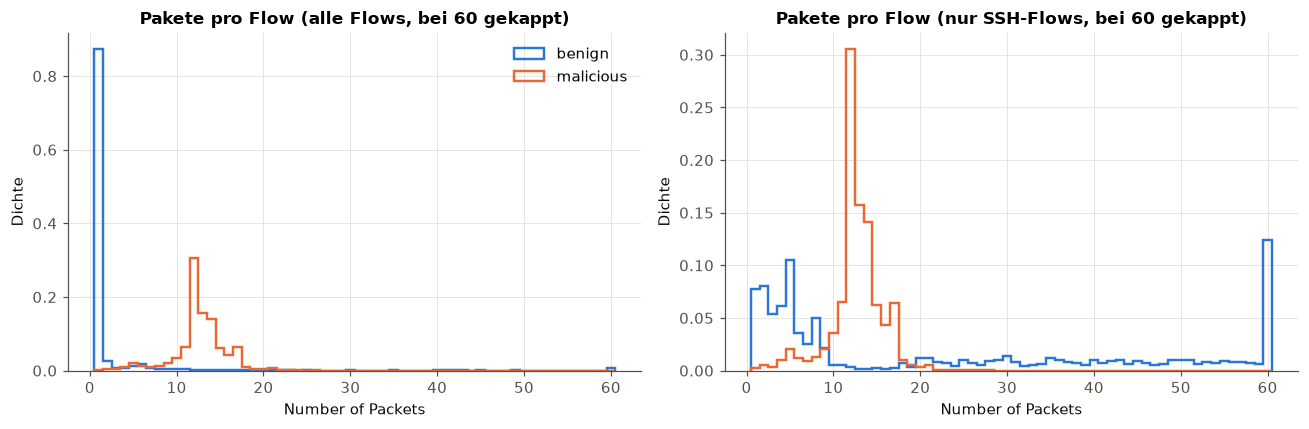

Häufigste Paketanzahlen bei malicious Flows:
{12: 0.305, 13: 0.158, 14: 0.141, 11: 0.065, 17: 0.065, 15: 0.062, 16: 0.044, 10: 0.035}


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (title, data) in zip(axes, [("alle Flows", raw), ("nur SSH-Flows", ssh)]):
    for label, color in CLASS_COLORS.items():
        v = data.loc[data["Label"] == label, "Number of Packets"].clip(upper=60)
        ax.hist(v, bins=np.arange(0.5, 61.5, 1), density=True, histtype="step", linewidth=1.6, color=color, label=label)
    ax.set_title(f"Pakete pro Flow ({title}, bei 60 gekappt)")
    ax.set_xlabel("Number of Packets")
    ax.set_ylabel("Dichte")
axes[0].legend()
plt.tight_layout()
plt.show()

print("Häufigste Paketanzahlen bei malicious Flows:")
print(raw.loc[raw["is_mal"] == 1, "Number of Packets"].value_counts(normalize=True).head(8).round(3).to_dict())

## 4. Ports & IP-Adressen

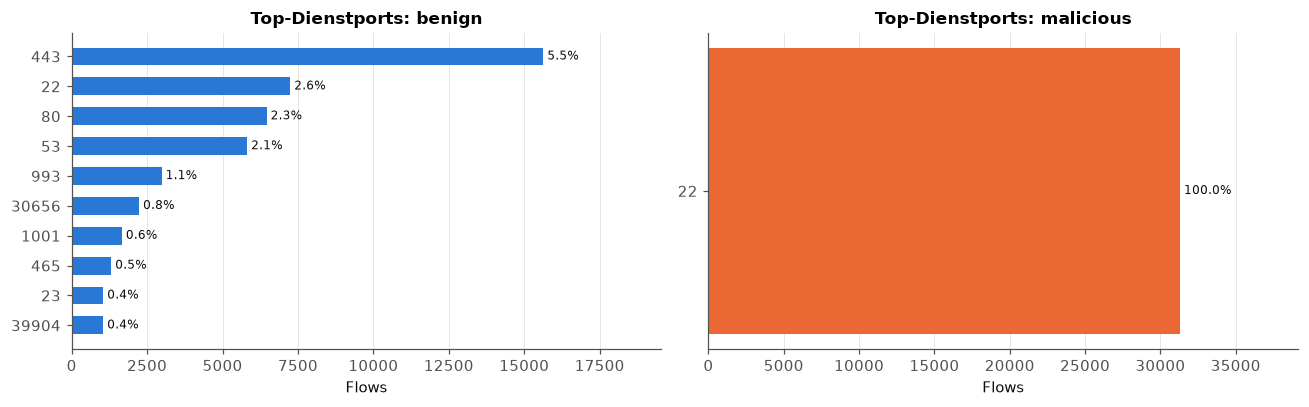

In [30]:
def top_ports(label, n=10):
    sub = raw[raw["Label"] == label]
    # "Dienst-Port" = der kleinere der beiden Ports eines Flows (Server-Seite)
    service = np.minimum(sub["Source Port"], sub["Destination Port"])
    return service.value_counts().head(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, label in zip(axes, ["benign", "malicious"]):
    tp = top_ports(label)
    total = (raw["Label"] == label).sum()
    ax.barh([str(p) for p in tp.index], tp.values, color=CLASS_COLORS[label], height=0.6)
    for i, v in enumerate(tp.values):
        ax.text(v, i, f" {v / total:.1%}", va="center", fontsize=8, color=INK)
    ax.invert_yaxis()
    ax.set_xlim(0, tp.max() * 1.25)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"Top-Dienstports: {label}")
    ax.set_xlabel("Flows")
plt.tight_layout()
plt.show()

Überwachter Server (häufigste IP): 37.60.229.253 – in 100.0% aller Flows
Flows mit Quelle == Server: 49.9%

Unterschiedliche Angreifer-IPs: 277
Unterschiedliche Gegenstellen in benignen Flows: 9,306
Angreifer-IPs, die auch benigne Flows haben: 81
Anteil der Angriffs-Flows durch die Top-10-Angreifer: 39.9%


,count,mean,std,min,25%,50%,75%,max
Flows pro Angreifer-IP,277.0000,113.0181,286.2303,2.0000,22.0000,40.0000,44.0000,"2,930.0000"


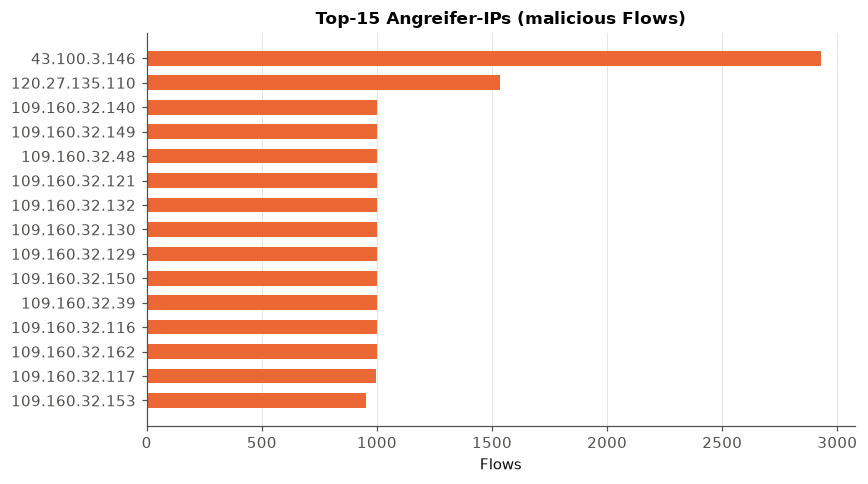

In [31]:
ip_counts = pd.concat([raw["Source IP"], raw["Destination IP"]]).value_counts()
SERVER_IP = ip_counts.index[0]
raw["peer_ip"] = np.where(raw["Source IP"] == SERVER_IP, raw["Destination IP"], raw["Source IP"])
print(f"Überwachter Server (häufigste IP): {SERVER_IP} – in {(raw['Source IP'].eq(SERVER_IP) | raw['Destination IP'].eq(SERVER_IP)).mean():.1%} aller Flows")
print(f"Flows mit Quelle == Server: {(raw['Source IP'] == SERVER_IP).mean():.1%}")

mal_peers = raw.loc[raw["is_mal"] == 1, "peer_ip"].value_counts()
ben_peers = raw.loc[raw["is_mal"] == 0, "peer_ip"]
print(f"\nUnterschiedliche Angreifer-IPs: {len(mal_peers):,}")
print(f"Unterschiedliche Gegenstellen in benignen Flows: {ben_peers.nunique():,}")
print(f"Angreifer-IPs, die auch benigne Flows haben: {len(set(mal_peers.index) & set(ben_peers)):,}")
print(f"Anteil der Angriffs-Flows durch die Top-10-Angreifer: {mal_peers.head(10).sum() / mal_peers.sum():.1%}")
display(mal_peers.describe().to_frame("Flows pro Angreifer-IP").T)

top = mal_peers.head(15)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color=C_MAL, height=0.6)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Top-15 Angreifer-IPs (malicious Flows)")
ax.set_xlabel("Flows")
plt.tight_layout()
plt.show()

Angreifer-IPs im Test-Teil: 150, davon im Training nie als Angreifer gesehen: 53
Malicious Test-Flows von neuen Angreifern: 5,902 von 7,446


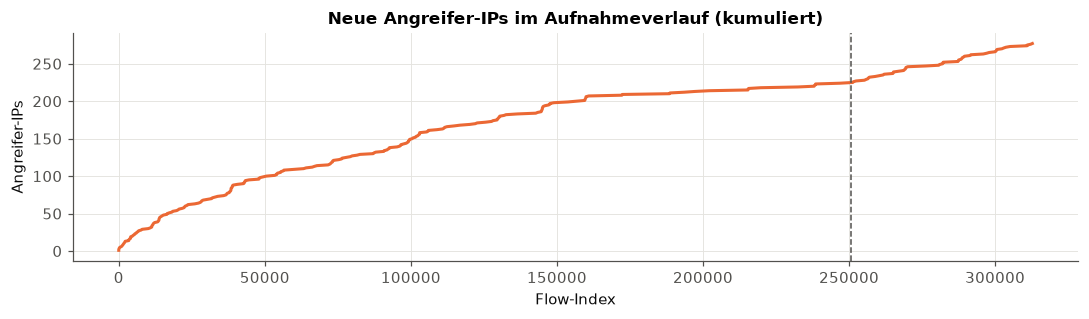

In [32]:
# Wann tauchen Angreifer zum ersten Mal auf? Relevant dafür, ob Test-Angreifer schon im Training gesehen wurden.
first_seen = raw[raw["is_mal"] == 1].groupby("peer_ip").apply(lambda g: g.index.min(), include_groups=False)
test_mal = raw.loc[split_idx:][raw.loc[split_idx:, "is_mal"] == 1]
unseen_attackers = set(first_seen[first_seen >= split_idx].index)
print(f"Angreifer-IPs im Test-Teil: {test_mal['peer_ip'].nunique():,}, davon im Training nie als Angreifer gesehen: {len(unseen_attackers):,}")
print(f"Malicious Test-Flows von neuen Angreifern: {test_mal['peer_ip'].isin(unseen_attackers).sum():,} von {len(test_mal):,}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.sort(first_seen.values), np.arange(1, len(first_seen) + 1), color=C_MAL)
ax.axvline(split_idx, color=INK_MUTED, linestyle="--", linewidth=1)
ax.set_title("Neue Angreifer-IPs im Aufnahmeverlauf (kumuliert)")
ax.set_xlabel("Flow-Index")
ax.set_ylabel("Angreifer-IPs")
plt.tight_layout()
plt.show()

## 5. Korrelationen & normalisierte Features

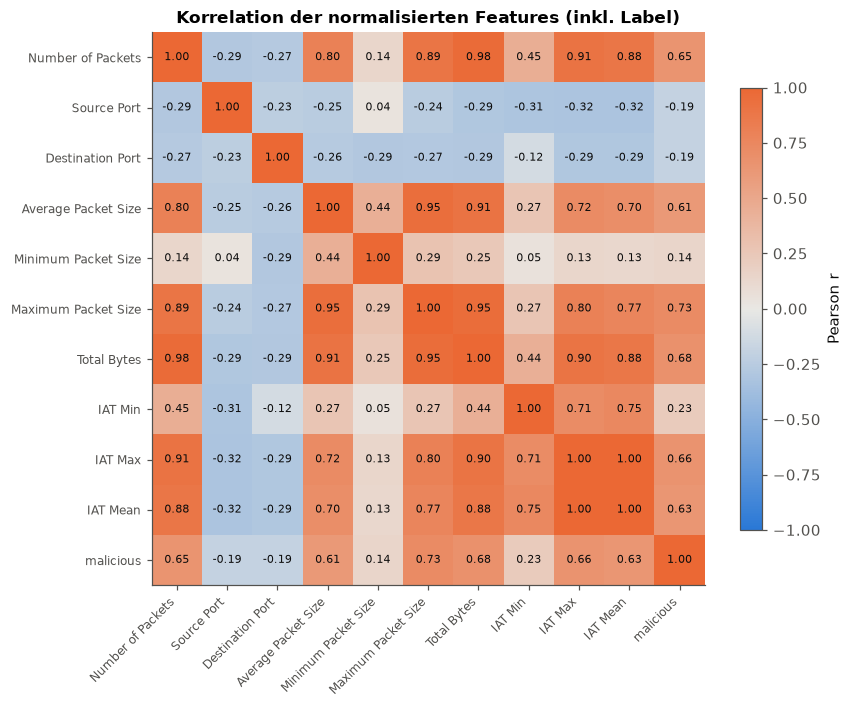

,r mit Label
Maximum Packet Size,0.7252
Total Bytes,0.6783
IAT Max,0.6586
Number of Packets,0.6501
IAT Mean,0.6334
Average Packet Size,0.6105
IAT Min,0.2251
Source Port,-0.1904
Destination Port,-0.1892
Minimum Packet Size,0.1421


In [33]:
norm = normalize_training_data(raw)
corr = norm[FEATURE_COLUMNS].assign(malicious=raw["is_mal"]).corr()

diverging = LinearSegmentedColormap.from_list("div", [C_BENIGN, "#e9e8e4", C_MAL])
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color=INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Korrelation der normalisierten Features (inkl. Label)")
plt.tight_layout()
plt.show()

corr["malicious"].drop("malicious").sort_values(key=abs, ascending=False).to_frame("r mit Label")

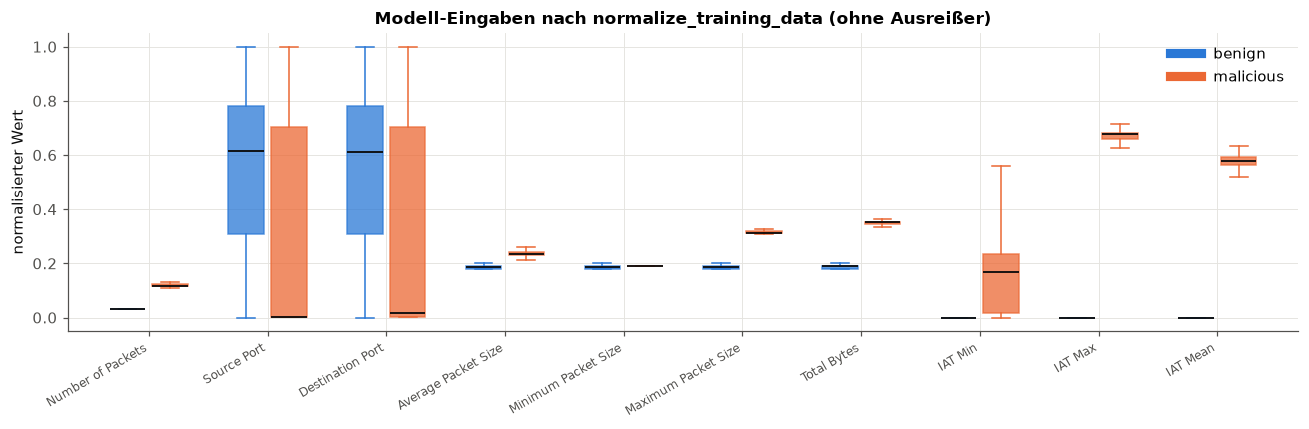

,min,max,mean,std
Number of Packets,0.0312,0.5015,0.0475,0.0353
Source Port,0.0000,1.0000,0.5224,0.3104
Destination Port,0.0000,1.0000,0.5219,0.3104
Average Packet Size,0.1807,0.4239,0.1940,0.0217
Minimum Packet Size,0.1807,0.3302,0.1863,0.0070
Maximum Packet Size,0.1807,0.4681,0.2053,0.0471
Total Bytes,0.1807,0.7938,0.2156,0.0641
IAT Min,0.0000,0.8237,0.0536,0.1431
IAT Max,0.0000,0.8259,0.1370,0.2662
IAT Mean,0.0000,0.8237,0.1225,0.2377


In [34]:
fig, ax = plt.subplots(figsize=(12, 4))
positions = np.arange(len(FEATURE_COLUMNS))
for offset, (label, color) in zip([-0.18, 0.18], CLASS_COLORS.items()):
    data = [norm.loc[norm["Label"] == label, c].values for c in FEATURE_COLUMNS]
    bp = ax.boxplot(data, positions=positions + offset, widths=0.3, showfliers=False, patch_artist=True,
                    medianprops=dict(color=INK, linewidth=1.2), whiskerprops=dict(color=color),
                    capprops=dict(color=color), boxprops=dict(facecolor=color, edgecolor=color, alpha=0.75))
    ax.plot([], [], color=color, linewidth=6, label=label)
ax.set_xticks(positions, FEATURE_COLUMNS, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("normalisierter Wert")
ax.set_title("Modell-Eingaben nach normalize_training_data (ohne Ausreißer)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

norm[FEATURE_COLUMNS].describe().T[["min", "max", "mean", "std"]]

## 6. Modelltraining

Wie in `model.main()`: Features normalisieren, chronologisch 80/20 splitten, `AttackDetectionNet().fit(...)`.
Einzige Abweichung: fester Seed (`SEED`) für Reproduzierbarkeit; das Modell wird nicht gespeichert.

In [35]:
x = torch.tensor(norm[FEATURE_COLUMNS].to_numpy(), dtype=torch.float32)
y = torch.tensor(raw["is_mal"].to_numpy(), dtype=torch.float32)
X_train, X_test = x[:split_idx], x[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
test_df = raw.iloc[split_idx:].reset_index(drop=True)
print(f"Train: {len(y_train):,} Flows ({int(y_train.sum()):,} malicious) | Test: {len(y_test):,} Flows ({int(y_test.sum()):,} malicious)")

torch.manual_seed(SEED)
model = AttackDetectionNet()
print(model)
print(f"Parameter: {sum(p.numel() for p in model.parameters()):,}")

Train: 250,591 Flows (23,860 malicious) | Test: 62,648 Flows (7,446 malicious)
AttackDetectionNet(
  (layers): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=8, bias=True)
    (5): ReLU()
    (6): Linear(in_features=8, out_features=1, bias=True)
  )
)
Parameter: 593


In [36]:
%%time
model.fit(list(zip(X_train, y_train)), epochs=EPOCHS, batch_size=BATCH_SIZE)

Training on cpu.
Epoch 1/20 completed. average loss: 0.10070114619980572
Epoch 2/20 completed. average loss: 0.05509895361823049
Epoch 3/20 completed. average loss: 0.04482040419647779
Epoch 4/20 completed. average loss: 0.04170567706002113
Epoch 5/20 completed. average loss: 0.03944709925572069
Epoch 6/20 completed. average loss: 0.03801676510854269
Epoch 7/20 completed. average loss: 0.03702520887391391
Epoch 8/20 completed. average loss: 0.035810995324173304
Epoch 9/20 completed. average loss: 0.035029743094125654
Epoch 10/20 completed. average loss: 0.03436261676937544
Epoch 11/20 completed. average loss: 0.03353272055129584
Epoch 12/20 completed. average loss: 0.03284048865794376
Epoch 13/20 completed. average loss: 0.03206473710529555
Epoch 14/20 completed. average loss: 0.03135316847151054
Epoch 15/20 completed. average loss: 0.030843630023190936
Epoch 16/20 completed. average loss: 0.02995532955369333
Epoch 17/20 completed. average loss: 0.029372982244137917
Epoch 18/20 complet

## 7. Evaluation auf dem Test-Split

In [37]:
def predict_scores(m, X):
    with torch.no_grad():
        return torch.sigmoid(m(X).squeeze(1)).numpy()


def roc_pr(y_true, scores):
    order = np.argsort(-scores, kind="mergesort")
    s, t = scores[order], y_true[order]
    distinct = np.r_[np.where(np.diff(s))[0], len(s) - 1]
    tp = np.cumsum(t)[distinct]
    fp = (distinct + 1) - tp
    P, N = t.sum(), len(t) - t.sum()
    tpr = np.r_[0, tp / P]
    fpr = np.r_[0, fp / N]
    precision = np.r_[1, tp / (tp + fp)]
    roc_auc = np.trapezoid(tpr, fpr)
    ap = np.sum(np.diff(tpr) * precision[1:])  # Average Precision
    return fpr, tpr, precision, roc_auc, ap


def metrics(y_true, y_pred, scores=None):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(((y_true == 1) & (y_pred == 1)).sum()); fp = int(((y_true == 0) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum()); fn = int(((y_true == 1) & (y_pred == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else np.nan
    rec = tp / (tp + fn) if tp + fn else np.nan
    spec = tn / (tn + fp) if tn + fp else np.nan
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    out = {
        "Flows": len(y_true), "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "Accuracy": (tp + tn) / len(y_true), "Precision": prec, "Recall": rec, "Specificity": spec,
        "F1": 2 * prec * rec / (prec + rec) if prec and rec else np.nan,
        "Balanced Acc.": (rec + spec) / 2, "MCC": (tp * tn - fp * fn) / denom if denom else np.nan,
        "FPR": fp / (fp + tn) if fp + tn else np.nan,
    }
    if scores is not None and 0 < y_true.sum() < len(y_true):
        _, _, _, auc, ap = roc_pr(y_true, scores)
        out["ROC-AUC"], out["PR-AUC (AP)"] = auc, ap
    return out


INT_COLS = ["Flows", "TP", "FP", "TN", "FN"]

def show(res):
    return pd.DataFrame(res).T.astype({c: int for c in INT_COLS})


y_true = y_test.int().numpy()
scores = predict_scores(model, X_test)
y_pred = (scores >= CUTOFF).astype(int)

# Ausgabe im Format von model.main()
print_metrics("All flows", torch.tensor(y_true), torch.tensor(y_pred))

-> All flows (62648 samples)
TP: 6990 (11.16 %), FP: 466 (0.74 %), TN: 54736 (87.37 %), FN: 456 (0.73 %)
Precision: 93.75 %
Recall: 93.88 %
F1 Score: 93.81 %


In [38]:
results = {"Modell – alle Test-Flows": metrics(y_true, y_pred, scores)}
show(results)

,Flows,TP,FP,TN,FN,Accuracy,Precision,Recall,Specificity,F1,Balanced Acc.,MCC,FPR,ROC-AUC,PR-AUC (AP)
Modell – alle Test-Flows,62648,6990,466,54736,456,0.9853,0.9375,0.9388,0.9916,0.9381,0.9652,0.9298,0.0084,0.9963,0.9819


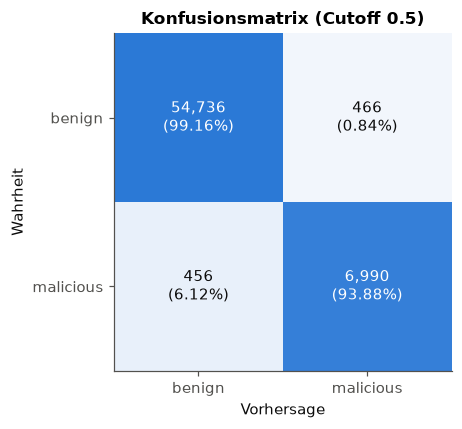

In [39]:
m = results["Modell – alle Test-Flows"]
cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
cm_norm = cm / cm.sum(axis=1, keepdims=True)
blues = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", C_BENIGN])

fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm_norm, cmap=blues, vmin=0, vmax=1)
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm_norm[i, j]:.2%})", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.6 else INK, fontsize=10)
ax.set_xticks([0, 1], ["benign", "malicious"])
ax.set_yticks([0, 1], ["benign", "malicious"])
ax.set_xlabel("Vorhersage")
ax.set_ylabel("Wahrheit")
ax.set_title(f"Konfusionsmatrix (Cutoff {CUTOFF})")
plt.tight_layout()
plt.show()

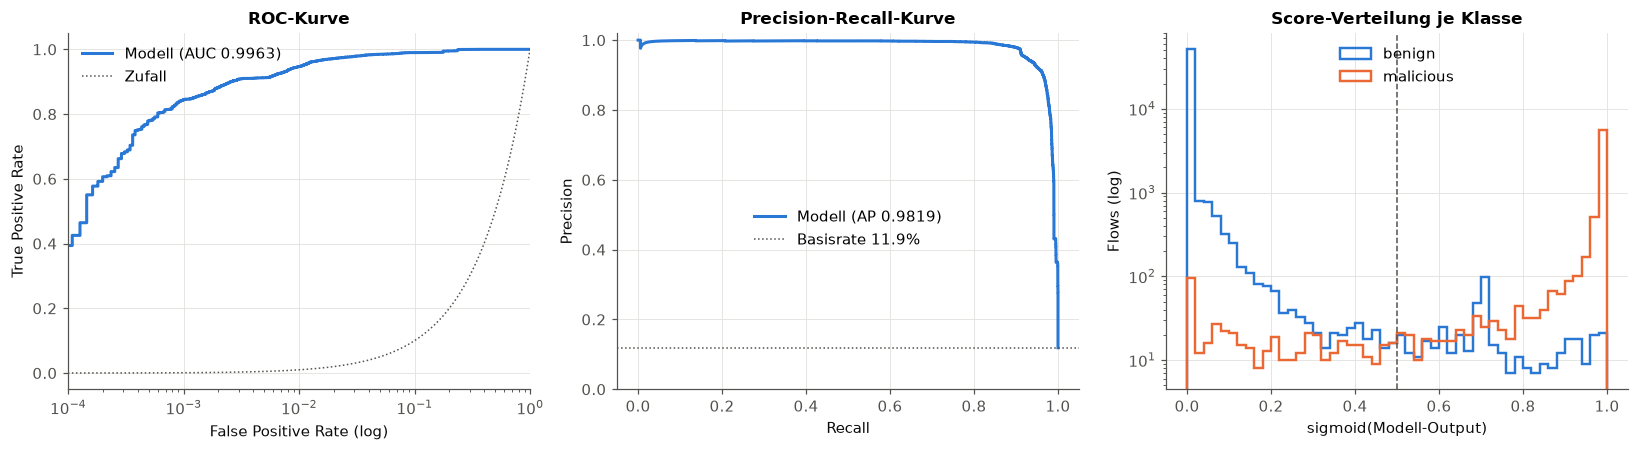

In [40]:
fpr, tpr, precision, auc, ap = roc_pr(y_true, scores)
base_rate = y_true.mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(fpr, tpr, color=C_BENIGN, label=f"Modell (AUC {auc:.4f})")
diag = np.logspace(-5, 0, 200)
axes[0].plot(diag, diag, color=INK_MUTED, linestyle=":", linewidth=1, label="Zufall")
axes[0].set_xscale("log")
axes[0].set_xlim(1e-4, 1)
axes[0].set_xlabel("False Positive Rate (log)")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC-Kurve")
axes[0].legend(loc="upper left")

axes[1].plot(tpr, precision, color=C_BENIGN, label=f"Modell (AP {ap:.4f})")
axes[1].axhline(base_rate, color=INK_MUTED, linestyle=":", linewidth=1, label=f"Basisrate {base_rate:.1%}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_ylim(0, 1.02)
axes[1].set_title("Precision-Recall-Kurve")
axes[1].legend(loc="center", bbox_to_anchor=(0.5, 0.45))

edges = np.linspace(0, 1, 51)
for label, color, cls in [("benign", C_BENIGN, 0), ("malicious", C_MAL, 1)]:
    axes[2].hist(scores[y_true == cls], bins=edges, color=color, histtype="step", linewidth=1.6, label=label)
axes[2].axvline(CUTOFF, color=INK_MUTED, linestyle="--", linewidth=1)
axes[2].set_yscale("log")
axes[2].set_xlabel("sigmoid(Modell-Output)")
axes[2].set_ylabel("Flows (log)")
axes[2].set_title("Score-Verteilung je Klasse")
axes[2].legend(loc="upper center")
plt.tight_layout()
plt.show()

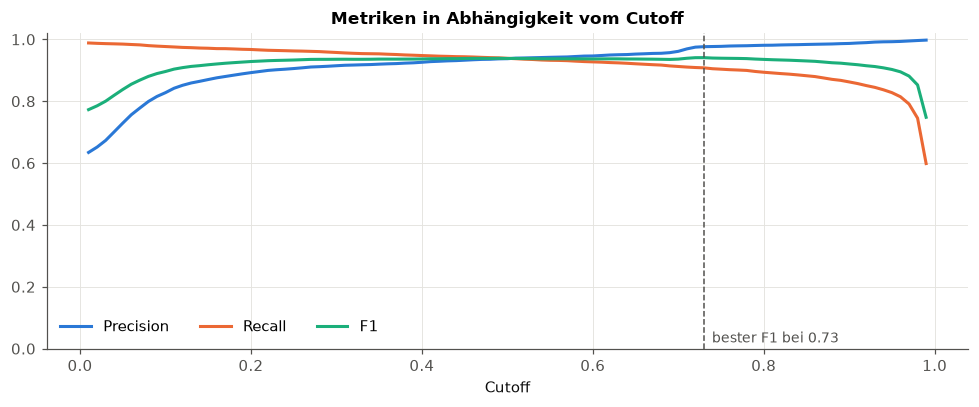

,TP,FP,FN,Precision,Recall,F1,FPR
Cutoff,,,,,,,
0.1000,7273,1514,173,0.8277,0.9768,0.8961,0.0274
0.3000,7130,665,316,0.9147,0.9576,0.9356,0.0120
0.5000,6990,466,456,0.9375,0.9388,0.9381,0.0084
0.7000,6793,274,653,0.9612,0.9123,0.9361,0.0050
0.9000,6421,86,1025,0.9868,0.8623,0.9204,0.0016
0.7300,6760,164,686,0.9763,0.9079,0.9408,0.0030


In [41]:
thresholds = np.round(np.linspace(0.01, 0.99, 99), 2)
sweep = pd.DataFrame([{"Cutoff": t, **metrics(y_true, (scores >= t).astype(int))} for t in thresholds]).set_index("Cutoff")

fig, ax = plt.subplots(figsize=(9, 3.8))
for col, color in [("Precision", C_BENIGN), ("Recall", C_MAL), ("F1", C_ALT)]:
    ax.plot(sweep.index, sweep[col], color=color, label=col)
best = sweep["F1"].idxmax()
ax.axvline(best, color=INK_MUTED, linestyle="--", linewidth=1)
ax.text(best, 0.02, f"  bester F1 bei {best:.2f}", color=INK_MUTED, fontsize=9)
ax.set_xlabel("Cutoff")
ax.set_ylim(0, 1.02)
ax.set_title("Metriken in Abhängigkeit vom Cutoff")
ax.legend(loc="lower left", ncol=3)
plt.tight_layout()
plt.show()

sweep.loc[[0.1, 0.3, CUTOFF, 0.7, 0.9, round(best, 2)], ["TP", "FP", "FN", "Precision", "Recall", "F1", "FPR"]].drop_duplicates()

## 8. Robustheit

Da sämtliche Angriffe auf Port 22 laufen und die Ports Teil der Features sind, könnte das Modell im Wesentlichen
„Port 22 → malicious“ gelernt haben. Prüfungen:

* **Nur SSH-Flows**: die eigentlich schwierige Teilmenge (Bruteforce vs. legitimes SSH)
* **Baseline**: Regel „Port 22 ⇒ malicious“ ohne Modell
* **Unbekannte Angreifer**: malicious Test-Flows von IPs, die im Training nie als Angreifer vorkamen
* **Ablation**: dasselbe Netz, trainiert mit auf 0 gesetzten Port-Features

In [42]:
ssh_mask = test_df["is_ssh"].to_numpy()
results["Modell – nur SSH-Flows"] = metrics(y_true[ssh_mask], y_pred[ssh_mask], scores[ssh_mask])
results["Baseline Port 22 – alle Flows"] = metrics(y_true, ssh_mask.astype(int))

show(results)

,Flows,TP,FP,TN,FN,Accuracy,Precision,Recall,Specificity,F1,Balanced Acc.,MCC,FPR,ROC-AUC,PR-AUC (AP)
Modell – alle Test-Flows,62648,6990,466,54736,456,0.9853,0.9375,0.9388,0.9916,0.9381,0.9652,0.9298,0.0084,0.9963,0.9819
Modell – nur SSH-Flows,8975,6990,118,1411,456,0.9360,0.9834,0.9388,0.9228,0.9606,0.9308,0.7980,0.0772,0.9757,0.9939
Baseline Port 22 – alle Flows,62648,7446,1529,53673,0,0.9756,0.8296,1.0000,0.9723,0.9069,0.9862,0.8981,0.0277,NaN,NaN


Erkennungsrate (Recall) für Angreifer, deren IP im Trainingsteil nie als Angreifer auftauchte, im Vergleich zu bereits
bekannten Angreifer-IPs. Precision ist hier nicht sinnvoll vergleichbar, da beide Gruppen dieselben benignen Flows teilen.

In [43]:
new_att = test_df["peer_ip"].isin(unseen_attackers).to_numpy()
by_group = []
for name, mask in [("neue Angreifer-IPs", new_att), ("bekannte Angreifer-IPs", ~new_att)]:
    sel = (y_true == 1) & mask
    by_group.append({"Gruppe": name, "IPs": test_df.loc[sel, "peer_ip"].nunique(), "malicious Flows": int(sel.sum()),
                     "erkannt": int(y_pred[sel].sum()), "Recall": y_pred[sel].mean(), "Median-Score": np.median(scores[sel])})
pd.DataFrame(by_group).set_index("Gruppe")

,IPs,malicious Flows,erkannt,Recall,Median-Score
Gruppe,,,,,
neue Angreifer-IPs,53,5902,5546,0.9397,0.9925
bekannte Angreifer-IPs,97,1544,1444,0.9352,0.9914


In [44]:
%%time
PORT_IDX = [FEATURE_COLUMNS.index("Source Port"), FEATURE_COLUMNS.index("Destination Port")]
x_np = x.clone()
x_np[:, PORT_IDX] = 0
X_train_np, X_test_np = x_np[:split_idx], x_np[split_idx:]

torch.manual_seed(SEED)
model_noport = AttackDetectionNet()
model_noport.fit(list(zip(X_train_np, y_train)), epochs=EPOCHS, batch_size=BATCH_SIZE)

Training on cpu.
Epoch 1/20 completed. average loss: 0.09642171501043469
Epoch 2/20 completed. average loss: 0.04942822310154647
Epoch 3/20 completed. average loss: 0.04530332141449465
Epoch 4/20 completed. average loss: 0.04265785744517528
Epoch 5/20 completed. average loss: 0.041061951850572216
Epoch 6/20 completed. average loss: 0.039316745486006
Epoch 7/20 completed. average loss: 0.03794704760565232
Epoch 8/20 completed. average loss: 0.03680110128460015
Epoch 9/20 completed. average loss: 0.03615262514910611
Epoch 10/20 completed. average loss: 0.035090059049893055
Epoch 11/20 completed. average loss: 0.034276475737712496
Epoch 12/20 completed. average loss: 0.0335779582640924
Epoch 13/20 completed. average loss: 0.03304596193865268
Epoch 14/20 completed. average loss: 0.03241461694928998
Epoch 15/20 completed. average loss: 0.03206890313944975
Epoch 16/20 completed. average loss: 0.03160612133829406
Epoch 17/20 completed. average loss: 0.03103508225656691
Epoch 18/20 completed. 

In [45]:
scores_np = predict_scores(model_noport, X_test_np)
y_pred_np = (scores_np >= CUTOFF).astype(int)
results["Ablation ohne Ports – alle Flows"] = metrics(y_true, y_pred_np, scores_np)
results["Ablation ohne Ports – nur SSH-Flows"] = metrics(y_true[ssh_mask], y_pred_np[ssh_mask], scores_np[ssh_mask])

summary = show(results)
summary[["Flows", "TP", "FP", "FN", "Precision", "Recall", "F1", "MCC", "FPR", "ROC-AUC", "PR-AUC (AP)"]]

,Flows,TP,FP,FN,Precision,Recall,F1,MCC,FPR,ROC-AUC,PR-AUC (AP)
Modell – alle Test-Flows,62648,6990,466,456,0.9375,0.9388,0.9381,0.9298,0.0084,0.9963,0.9819
Modell – nur SSH-Flows,8975,6990,118,456,0.9834,0.9388,0.9606,0.7980,0.0772,0.9757,0.9939
Baseline Port 22 – alle Flows,62648,7446,1529,0,0.8296,1.0000,0.9069,0.8981,0.0277,NaN,NaN
Ablation ohne Ports – alle Flows,62648,7029,512,417,0.9321,0.9440,0.9380,0.9296,0.0093,0.9943,0.9816
Ablation ohne Ports – nur SSH-Flows,8975,7029,92,417,0.9871,0.9440,0.9651,0.8207,0.0602,0.9793,0.9948


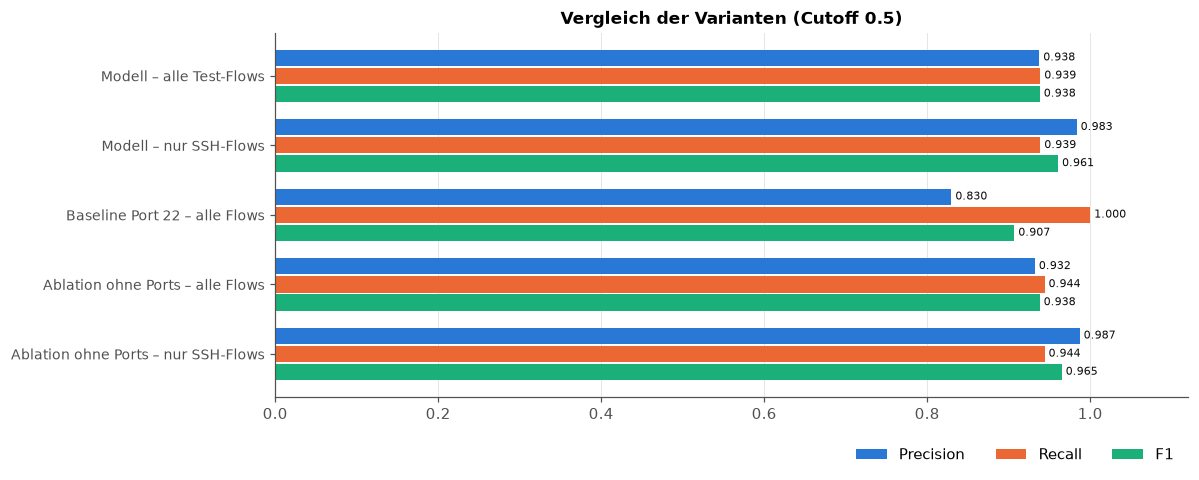

In [46]:
plot_rows = ["Modell – alle Test-Flows", "Modell – nur SSH-Flows", "Baseline Port 22 – alle Flows",
             "Ablation ohne Ports – alle Flows", "Ablation ohne Ports – nur SSH-Flows"]
plot_metrics = [("Precision", C_BENIGN), ("Recall", C_MAL), ("F1", C_ALT)]
fig, ax = plt.subplots(figsize=(11, 4.5))
ypos = np.arange(len(plot_rows))
h = 0.26
for k, (metric, color) in enumerate(plot_metrics):
    vals = summary.loc[plot_rows, metric].astype(float).values
    ax.barh(ypos + (k - 1) * h, vals, height=h * 0.9, color=color, label=metric)
    for yy, v in zip(ypos + (k - 1) * h, vals):
        ax.text(v, yy, f" {v:.3f}", va="center", fontsize=7, color=INK)
ax.set_yticks(ypos, plot_rows, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.grid(axis="y", visible=False)
ax.set_title(f"Vergleich der Varianten (Cutoff {CUTOFF})")
ax.legend(loc="lower right", ncol=3, bbox_to_anchor=(1, -0.22))
plt.tight_layout()
plt.show()

## 9. Feature Importance

**Permutation Importance:** Für jedes Feature werden dessen Werte im Test-Set zufällig permutiert (übrige Features
unverändert) und der Score neu berechnet. Der Abfall von ROC-AUC bzw. F1 (Cutoff 0.5) gegenüber den unveränderten Daten
misst, wie stark sich das Modell auf dieses Feature verlässt. Jeweils `N_REPEATS` Permutationen; Fehlerbalken = Standardabweichung.

Ausgewertet für das Modell auf allen Test-Flows und nur auf SSH-Flows sowie für das Ablationsmodell ohne Ports (nur SSH).

In [47]:
N_REPEATS = 10


def permutation_importance(m, X, y_true, n_repeats=N_REPEATS, seed=SEED):
    rng = np.random.default_rng(seed)
    base_scores = predict_scores(m, X)
    base_auc = roc_pr(y_true, base_scores)[3]
    base_f1 = metrics(y_true, (base_scores >= CUTOFF).astype(int))["F1"]
    rows = []
    for j, col in enumerate(FEATURE_COLUMNS):
        d_auc, d_f1 = [], []
        for _ in range(n_repeats):
            Xp = X.clone()
            Xp[:, j] = Xp[torch.from_numpy(rng.permutation(len(Xp))), j]
            s = predict_scores(m, Xp)
            d_auc.append(base_auc - roc_pr(y_true, s)[3])
            d_f1.append(base_f1 - metrics(y_true, (s >= CUTOFF).astype(int))["F1"])
        rows.append({"Feature": col, "Δ ROC-AUC": np.mean(d_auc), "Δ ROC-AUC std": np.std(d_auc),
                     "Δ F1": np.mean(d_f1), "Δ F1 std": np.std(d_f1)})
    return pd.DataFrame(rows).set_index("Feature")


ssh_t = torch.from_numpy(ssh_mask)
importance = {
    "Modell – alle Test-Flows": permutation_importance(model, X_test, y_true),
    "Modell – nur SSH-Flows": permutation_importance(model, X_test[ssh_t], y_true[ssh_mask]),
    "Ablation ohne Ports – nur SSH-Flows": permutation_importance(model_noport, X_test_np[ssh_t], y_true[ssh_mask]),
}
pd.concat({k: v[["Δ ROC-AUC", "Δ F1"]] for k, v in importance.items()}, axis=1).sort_values(
    ("Modell – alle Test-Flows", "Δ F1"), ascending=False)

/tmp/ipykernel_1460185/2066695806.py:23: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  ssh_t = torch.from_numpy(ssh_mask)


Modell – alle Test-Flows        Modell – nur SSH-Flows         Ablation ohne Ports – nur SSH-Flows        
                                   Δ ROC-AUC   Δ F1              Δ ROC-AUC    Δ F1                           Δ ROC-AUC    Δ F1
Feature                                                                                                                       
IAT Max                               0.0970 0.6750                 0.0421  0.0468                              0.0361  0.0508
Number of Packets                     0.2125 0.6661                 0.2091  0.1002                              0.2561  0.0976
IAT Mean                              0.7030 0.6232                 0.0282  0.0174                              0.0321  0.0224
Source Port                           0.1348 0.1775                 0.1228  0.1197                              0.0000  0.0000
Destination Port                      0.1297 0.1680                 0.1184  0.1208                              0.0000  0.0000
Maximum Packet Size                   0.0058 0.0608                 0.0082  0.0030                              0.0057  0.0032
Total Bytes                           0.0069 0.0600                 0.0293  0.0130                              0.0212  0.0130
IAT Min                               0.0019 0.0445                 0.0060  0.0085                             -0.0007  0.0011
Average Packet Size                   0.0021 0.0321                 0.0012 -0.0004                              0.0013 -0.0006
Minimum Packet Size                   0.0001 0.0035                 0.0002  0.0004                              0.0000  0.0003

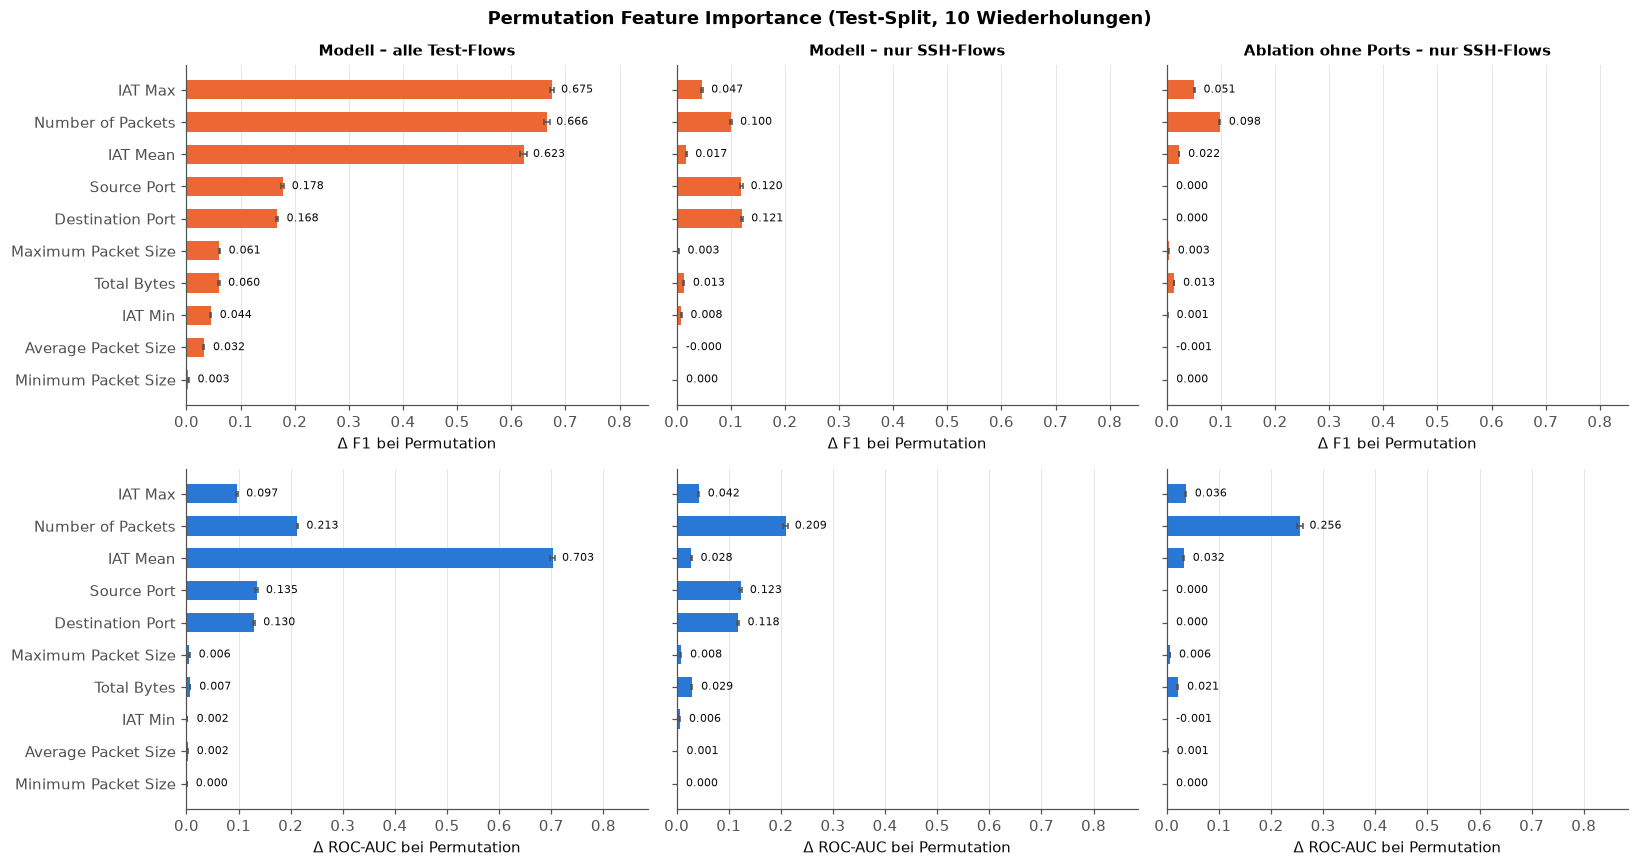

In [48]:
order = importance["Modell – alle Test-Flows"]["Δ F1"].sort_values().index  # wichtigstes Feature oben
panels = list(importance.items())
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for row, (metric, color) in enumerate([("Δ F1", C_MAL), ("Δ ROC-AUC", C_BENIGN)]):
    lim = max(imp[metric].max() + imp[f"{metric} std"].max() for _, imp in panels) * 1.25
    for ax, (title, imp) in zip(axes[row], panels):
        imp = imp.loc[order]
        ax.barh(imp.index, imp[metric].clip(lower=0), xerr=imp[f"{metric} std"], color=color, height=0.6,
                error_kw=dict(ecolor=INK_MUTED, elinewidth=1, capsize=2))
        for yy, v in enumerate(imp[metric]):
            ax.text(max(v, 0) + lim * 0.02, yy, f"{v:.3f}", va="center", fontsize=7, color=INK)
        ax.set_xlim(0, lim)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel(f"{metric} bei Permutation")
        if row == 0:
            ax.set_title(title, fontsize=10)
fig.suptitle(f"Permutation Feature Importance (Test-Split, {N_REPEATS} Wiederholungen)", fontweight="bold")
plt.tight_layout()
plt.show()

Ergänzend eine gradientenbasierte Sicht: **Gradient × Input** misst lokal pro Flow, wie stark der Modell-Output auf ein
Feature reagiert, gewichtet mit dessen Wert. Gezeigt wird der mittlere Betrag getrennt nach wahrer Klasse (Modell mit Ports).

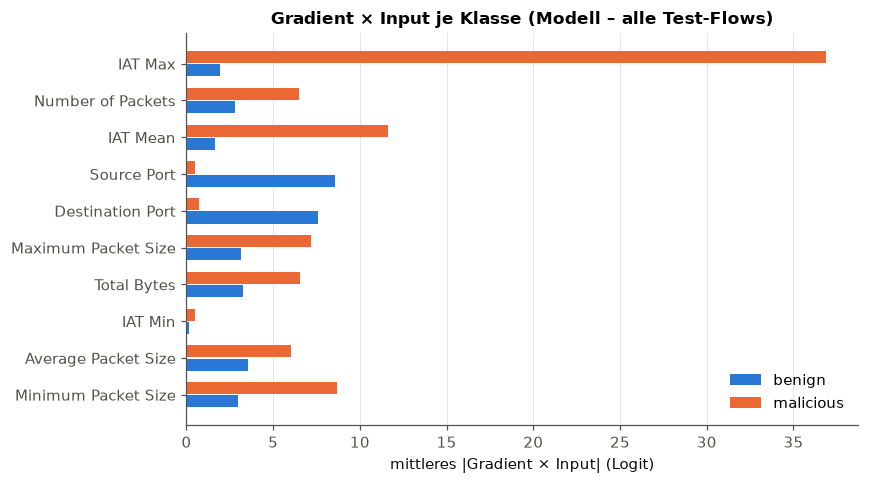

In [49]:
Xg = X_test.clone().requires_grad_(True)
model(Xg).sum().backward()
attr = (Xg.grad * X_test).abs().numpy()
gxi = pd.DataFrame({label: attr[y_true == cls].mean(axis=0) for label, cls in [("benign", 0), ("malicious", 1)]},
                   index=FEATURE_COLUMNS).loc[order]

fig, ax = plt.subplots(figsize=(8, 4.5))
ypos = np.arange(len(gxi))
for k, (label, color) in enumerate(CLASS_COLORS.items()):
    ax.barh(ypos + (k - 0.5) * 0.36, gxi[label], height=0.33, color=color, label=label)
ax.set_yticks(ypos, gxi.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("mittleres |Gradient × Input| (Logit)")
ax.set_title("Gradient × Input je Klasse (Modell – alle Test-Flows)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10. Fehleranalyse

In [50]:
err = test_df.assign(score=scores, pred=y_pred)
err["Fall"] = np.select(
    [(err.is_mal == 1) & (err.pred == 1), (err.is_mal == 0) & (err.pred == 1),
     (err.is_mal == 1) & (err.pred == 0), (err.is_mal == 0) & (err.pred == 0)],
    ["TP", "FP", "FN", "TN"], default="?")
cols = ["Number of Packets", "Average Packet Size", "Total Bytes", "IAT Mean"]
display(err.groupby("Fall")[cols + ["score"]].median().assign(Flows=err["Fall"].value_counts()))

print("False Positives nach Dienstport:")
fp_ports = np.minimum(err.loc[err.Fall == "FP", "Source Port"], err.loc[err.Fall == "FP", "Destination Port"]).value_counts().head(10)
print(fp_ports.to_dict())
print("\nFalse Negatives – Paketanzahl:")
print(err.loc[err.Fall == "FN", "Number of Packets"].value_counts().head(10).to_dict())
print("\nFalse Negatives – Top-Angreifer-IPs:")
print(err.loc[err.Fall == "FN", "peer_ip"].value_counts().head(10).to_dict())

,Number of Packets,Average Packet Size,Total Bytes,IAT Mean,score,Flows
Fall,,,,,,
FN,7.0000,129.2500,"1,265.5000",0.4916,0.1720,456
FP,10.0000,120.6667,"1,202.5000",0.1560,0.7053,466
TN,1.0000,60.0000,66.0000,0.0000,0.0000,54736
TP,13.0000,183.3333,"2,530.0000",0.3546,0.9928,6990


False Positives nach Dienstport:
{80: 189, 22: 118, 443: 80, 465: 42, 993: 14, 25: 9, 143: 5, 587: 4, 6443: 4, 53: 1}

False Negatives – Paketanzahl:
{5: 49, 6: 48, 4: 39, 1: 39, 10: 31, 2: 25, 9: 25, 11: 22, 13: 21, 3: 20}

False Negatives – Top-Angreifer-IPs:
{'109.160.32.121': 52, '77.239.124.69': 46, '116.99.168.110': 43, '109.160.32.132': 34, '109.160.32.130': 30, '27.79.41.27': 21, '109.160.32.162': 18, '102.220.160.39': 15, '102.220.161.86': 14, '102.220.161.174': 13}


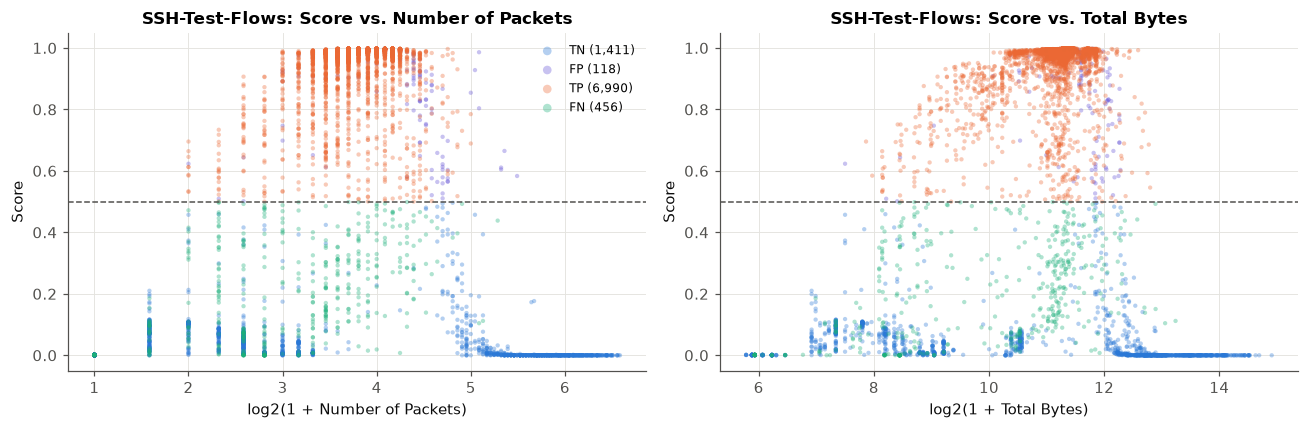

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ssh_err = err[err["is_ssh"]]
for ax, col in zip(axes, ["Number of Packets", "Total Bytes"]):
    for case, color in [("TN", C_BENIGN), ("FP", "#6250d6"), ("TP", C_MAL), ("FN", C_ALT)]:
        v = ssh_err.loc[ssh_err["Fall"] == case, col]
        if len(v):
            ax.scatter(np.log2(1 + v), ssh_err.loc[v.index, "score"], s=8, alpha=0.35, color=color, label=f"{case} ({len(v):,})", edgecolors="none")
    ax.set_xlabel(f"log2(1 + {col})")
    ax.set_ylabel("Score")
    ax.axhline(CUTOFF, color=INK_MUTED, linestyle="--", linewidth=1)
    ax.set_title(f"SSH-Test-Flows: Score vs. {col}")
axes[0].legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()

## Fazit

_wird nach Ausführung ergänzt_